# GWP2 — Methodology & Model Development

This notebook implements and demonstrates the two core models used in the
mini-capstone: a from-scratch **Hidden Markov Model** (regime detection)
and a **Bayesian network** (`pgmpy` Hill-Climbing structure + parameter
learning) over the discretized panel. It imports the cleaned data produced
by `GWP1_problem_formulation_and_data.ipynb` and reusable logic from
`oilbn.models`.

## Step 1 — Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oilbn.models import HiddenMarkovRegimeModel, OilPriceBayesianNetwork, label_states_by_mean
from oilbn.utils import PROJECT_ROOT

DATA_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reports" / "GWP2" / "figures"
TABLES_DIR = PROJECT_ROOT / "reports" / "GWP2" / "tables"
SECTIONS_DIR = PROJECT_ROOT / "reports" / "GWP2" / "sections"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)
SECTIONS_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 110
np.random.seed(0)

monthly_panel = pd.read_csv(DATA_DIR / "gwp1_monthly_panel.csv", index_col="date", parse_dates=True)
wti_daily = pd.read_csv(DATA_DIR / "wti_futures.csv", index_col="date", parse_dates=True)
wti_daily = wti_daily["wti_futures"]
brent_daily = pd.read_csv(DATA_DIR / "brent_futures.csv", index_col="date", parse_dates=True)[
    "brent_futures"
]

print(f"Monthly panel shape: {monthly_panel.shape}")
print(
    f"WTI daily series: {wti_daily.index.min().date()} -> "
    f"{wti_daily.index.max().date()}, n={len(wti_daily)}"
)
print(
    f"Brent daily series: {brent_daily.index.min().date()} -> "
    f"{brent_daily.index.max().date()}, n={len(brent_daily)}"
)

Monthly panel shape: (1293, 24)
WTI daily series: 2000-08-23 -> 2026-10-06, n=6558
Brent daily series: 2007-07-30 -> 2026-10-06, n=4776


c:\Users\fdeba001\Downloads\WQU\.venv-2\Lib\site-packages\pgmpy\estimators\__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


## Step 2 — Hidden Markov Model: toy example walkthrough

Before applying the model to real oil-price data, we demonstrate each of
the four classic algorithms (Rabiner & Juang) on a small, well-separated
two-state toy model (state 0 emits observations near $-5$, state 1 emits
observations near $+5$), so the mechanics of each step are transparent:

- **Forward** (Student A): evaluate $P(O \mid \lambda)$.
- **Backward** (Student A): the complementary tail-probability recursion.
- **Viterbi** (Student B): decode the single most likely hidden-state path.
- **Baum-Welch** (Student C): re-estimate $\lambda$ from unlabelled data.

In [2]:
# Hand-specified toy model: no fitting needed, parameters chosen for clarity.
toy_model = HiddenMarkovRegimeModel(n_states=2, random_state=0)
toy_model.startprob_ = np.array([0.5, 0.5])
toy_model.transmat_ = np.array([[0.9, 0.1], [0.1, 0.9]])
toy_model.means_ = np.array([-5.0, 5.0])
toy_model.variances_ = np.array([1.0, 1.0])

toy_observations = np.array([-5.1, -4.9, -5.0, 5.0, 4.9, 5.1])

# --- Forward (Evaluation): P(O | lambda) ---
log_alpha, log_likelihood = toy_model.forward(toy_observations)
print("Forward algorithm")
print(f"  log P(O | lambda) = {log_likelihood:.4f}  (P(O | lambda) = {np.exp(log_likelihood):.3e})")

# --- Backward (Evaluation, complementary direction) ---
log_beta = toy_model.backward(toy_observations)
gamma = np.exp(log_alpha + log_beta - log_likelihood)
print("\nBackward algorithm")
print(f"  gamma (posterior state probabilities) row-sums: {gamma.sum(axis=1).round(6)}")

# --- Viterbi (Decoding): single most likely state path ---
states, path_log_prob = toy_model.viterbi(toy_observations)
print("\nViterbi algorithm")
print(f"  decoded states: {states.tolist()}")
print(f"  log P(best path, O | lambda) = {path_log_prob:.4f}")

Forward algorithm
  log P(O | lambda) = -8.9508  (P(O | lambda) = 1.296e-04)

Backward algorithm
  gamma (posterior state probabilities) row-sums: [1. 1. 1. 1. 1. 1.]

Viterbi algorithm
  decoded states: [0, 0, 0, 1, 1, 1]
  log P(best path, O | lambda) = -8.9508


Baum-Welch algorithm
  iterations to convergence: 5
  log-likelihood monotonically non-decreasing: True
  true means:   [np.float64(-5.0), np.float64(5.0)]
  fitted means: [np.float64(-5.047), np.float64(4.891)]
  true transmat diag:   [0.9 0.9]
  fitted transmat diag: [0.9 0.9]


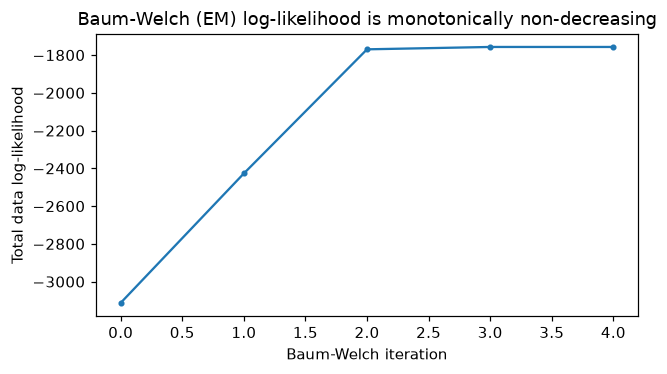

In [3]:
# --- Baum-Welch (Training): recover lambda from unlabelled simulated data ---
simulated_observations, true_states = toy_model.sample(1000, random_state=42)

learner = HiddenMarkovRegimeModel(n_states=2, n_iter=100, tol=1e-6, random_state=7)
learner.fit(simulated_observations)

history = np.array(learner.log_likelihood_history_)
print("Baum-Welch algorithm")
print(f"  iterations to convergence: {learner.n_iter_}")
print(f"  log-likelihood monotonically non-decreasing: {bool(np.all(np.diff(history) >= -1e-8))}")
print(f"  true means:   {sorted(toy_model.means_.round(3))}")
print(f"  fitted means: {sorted(learner.means_.round(3))}")
print(f"  true transmat diag:   {np.diag(toy_model.transmat_).round(3)}")
print(f"  fitted transmat diag: {np.diag(learner.transmat_).round(3)}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(history, marker="o", markersize=3)
ax.set_xlabel("Baum-Welch iteration")
ax.set_ylabel("Total data log-likelihood")
ax.set_title("Baum-Welch (EM) log-likelihood is monotonically non-decreasing")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "baum_welch_toy_convergence.png", dpi=150)
plt.show()

## Step 3 — Regime detection on real oil-price data (bull/bear/stagnant)

Fit a 3-state `HiddenMarkovRegimeModel` on daily log returns of WTI and
Brent futures (the cleaned series from GWP1). States are labelled
bear/stagnant/bull by ranking the fitted emission means
(`label_states_by_mean`).

In [ ]:
REGIME_COLORS = {"bear": "#d62728", "stagnant": "#7f7f7f", "bull": "#2ca02c"}


def fit_regime_model(price: pd.Series, n_states: int = 3, random_state: int = 0):
    """Fit a HiddenMarkovRegimeModel on daily log returns and decode regimes."""
    log_returns = np.log(price).diff().dropna()
    model = HiddenMarkovRegimeModel(
        n_states=n_states, n_iter=200, tol=1e-6, random_state=random_state
    )
    model.fit(log_returns.to_numpy())
    labels = label_states_by_mean(model)
    states = model.predict(log_returns.to_numpy())
    regimes = pd.Series([labels[s] for s in states], index=log_returns.index, name="regime")
    return model, regimes, log_returns


def plot_price_with_regimes(price: pd.Series, regimes: pd.Series, name: str, save_path: Path):
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(price.index, price.values, color="black", linewidth=0.6)
    for regime_name, color in REGIME_COLORS.items():
        mask = regimes == regime_name
        mask = mask.reindex(regimes.index, fill_value=False)
        ax.fill_between(
            regimes.index,
            price.min(),
            price.max(),
            where=mask,
            color=color,
            alpha=0.15,
            step="mid",
            label=regime_name,
        )
    ax.set_title(f"{name}: price level with decoded HMM regimes")
    ax.set_xlabel("Date")
    ax.set_ylabel("USD per barrel")
    ax.legend(loc="upper left", ncols=3, fontsize=8)
    fig.tight_layout()
    fig.savefig(save_path, dpi=150)
    plt.show()


def regime_duration_stats(regimes: pd.Series) -> pd.DataFrame:
    """Mean/median spell duration (in trading days) per regime."""
    frame = pd.DataFrame({"regime_label": regimes.to_numpy()})
    frame["spell_id"] = frame["regime_label"].ne(frame["regime_label"].shift()).cumsum()
    spells = frame.groupby("spell_id").agg(
        regime_label=("regime_label", "first"), duration=("regime_label", "size")
    )
    stats = spells.groupby("regime_label")["duration"].agg(["count", "mean", "median", "max"])
    return stats.round(1)


wti_model, wti_regimes, wti_log_returns = fit_regime_model(wti_daily, random_state=0)
plot_price_with_regimes(wti_daily, wti_regimes, "WTI futures", FIGURES_DIR / "wti_regimes.png")
print("WTI regime spell durations (trading days):")
wti_duration_stats = regime_duration_stats(wti_regimes)
print(wti_duration_stats)

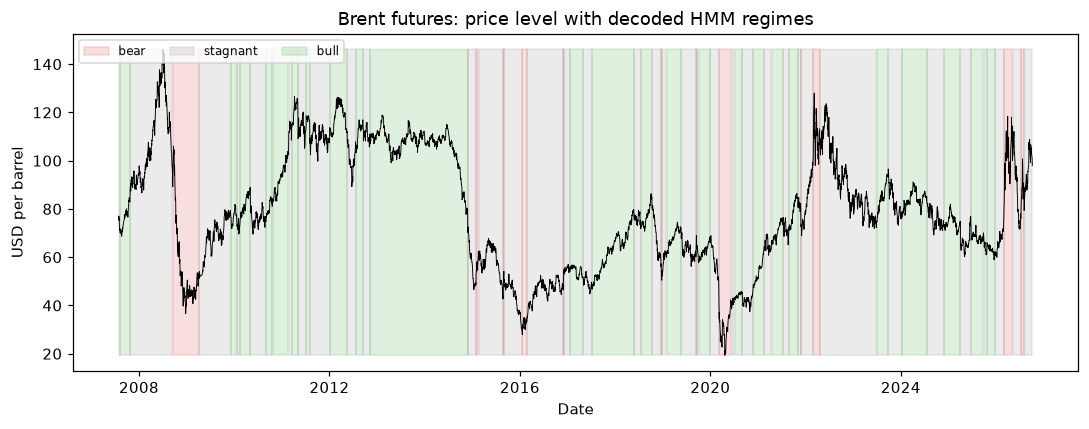

Brent regime spell durations (trading days):
              count  mean  median  max
regime_label                          
bear             13  27.8    12.0  134
bull             24  83.9    60.5  503
stagnant         37  64.8    45.0  299


In [8]:
brent_model, brent_regimes, brent_log_returns = fit_regime_model(brent_daily, random_state=0)
plot_price_with_regimes(
    brent_daily, brent_regimes, "Brent futures", FIGURES_DIR / "brent_regimes.png"
)
print("Brent regime spell durations (trading days):")
brent_duration_stats = regime_duration_stats(brent_regimes)
print(brent_duration_stats)

## Step 4 — Build a discrete, monthly regime/tercile panel

To feed the Bayesian network, every variable in the GWP1 panel must be
discrete. The two headline price series get their HMM-decoded
bear/stagnant/bull regime label (resampled to month-end via the mode).
Every other (macro/geopolitical) series is discretized into terciles
(low/medium/high) of its month-over-month change, since the *level* of
e.g. industrial production is non-stationary but its *change* is what is
economically comparable across the sample.

In [9]:
# Resample daily regime labels to monthly by taking the mode (most common regime that month).
wti_regime_monthly = wti_regimes.resample("ME").agg(lambda x: x.mode().iat[0])
wti_regime_monthly = wti_regime_monthly.rename("wti_regime")
brent_regime_monthly = brent_regimes.resample("ME").agg(lambda x: x.mode().iat[0])
brent_regime_monthly = brent_regime_monthly.rename("brent_regime")

OTHER_SERIES = [c for c in monthly_panel.columns if c not in ("wti_futures", "brent_futures")]


def tercile_label(change: pd.Series) -> pd.Series:
    """Discretize a numeric series into low/medium/high terciles."""
    return pd.qcut(change, q=3, labels=["low", "medium", "high"])


discrete_columns = {"wti_regime": wti_regime_monthly, "brent_regime": brent_regime_monthly}
for name in OTHER_SERIES:
    monthly_change = monthly_panel[name].pct_change()
    valid = monthly_change.dropna()
    if valid.nunique() < 3:
        continue
    discrete_columns[f"{name}_chg"] = tercile_label(valid).reindex(monthly_panel.index)

discrete_panel = pd.DataFrame(discrete_columns).dropna()
discrete_panel = discrete_panel.astype(str)
print(f"Discrete panel shape: {discrete_panel.shape}")
print(f"Columns: {list(discrete_panel.columns)}")
discrete_panel.head()

Discrete panel shape: (166, 24)
Columns: ['wti_regime', 'brent_regime', 'usd_index_chg', 'sp500_chg', 'ust10y_yield_chg', 'cpi_energy_chg', 'capacity_oil_gas_extraction_chg', 'capacity_util_oil_gas_extraction_chg', 'indprod_oil_gas_extraction_chg', 'indprod_crude_petroleum_ng_chg', 'indprod_total_chg', 'indprod_oil_gas_support_chg', 'ppi_oil_gas_extraction_chg', 'supply_non_opec_chg', 'supply_opec_chg', 'demand_oecd_chg', 'demand_non_oecd_chg', 'us_crude_production_chg', 'us_refinery_input_chg', 'oecd_inventory_balance_chg', 'opec_spare_capacity_chg', 'opec_production_capacity_chg', 'oecd_stock_change_chg', 'non_oecd_stock_change_chg']


,wti_regime,brent_regime,usd_index_chg,sp500_chg,ust10y_yield_chg,cpi_energy_chg,capacity_oil_gas_extraction_chg,capacity_util_oil_gas_extraction_chg,indprod_oil_gas_extraction_chg,indprod_crude_petroleum_ng_chg,...,supply_opec_chg,demand_oecd_chg,demand_non_oecd_chg,us_crude_production_chg,us_refinery_input_chg,oecd_inventory_balance_chg,opec_spare_capacity_chg,opec_production_capacity_chg,oecd_stock_change_chg,non_oecd_stock_change_chg
date,,,,,,,,,,,,,,,,,,,,,
2007-07-31,bull,stagnant,low,low,low,medium,medium,high,high,low,...,high,medium,low,low,high,high,low,high,low,medium
2007-08-31,bull,bull,medium,medium,low,low,medium,medium,medium,low,...,low,medium,low,low,medium,low,high,low,medium,medium
2007-09-30,bull,bull,low,high,medium,high,medium,medium,medium,low,...,high,medium,high,low,low,low,low,high,high,high
2007-10-31,bull,bull,low,medium,medium,high,medium,high,high,high,...,high,high,medium,high,low,low,low,low,high,medium
2007-11-30,stagnant,stagnant,medium,low,low,high,medium,high,high,medium,...,medium,medium,low,medium,medium,low,high,medium,high,medium


## Step 5 — Bayesian network: Hill-Climbing structure + parameter learning

`max_indegree=3` caps the search space given only 166 monthly
observations across 24 variables (avoids an overfit, densely-connected
graph). Structure is scored by BIC (`"bic-d"`); parameters are then
estimated with a Bayesian (BDeu-prior) estimator, which is more robust to
parent-value combinations seen only a handful of times in a sample this
small.

In [10]:
bn = OilPriceBayesianNetwork(scoring_method="bic-d", max_indegree=3, tabu_length=50)
bn.fit(discrete_panel, estimator="bayesian")

print(f"Learned {len(bn.edges)} edges:")
for parent, child in sorted(bn.edges):
    print(f"  {parent} -> {child}")

C:\Users\fdeba001\Downloads\WQU\oil-price-risk-capstone\src\oilbn\models\bayesian_network.py:77: FutureWarning: HillClimbSearch is deprecated and will be removed in v1.3.0. Please use
            pgmpy.causal_discovery.HillClimbSearch instead.
  searcher = HillClimbSearch(data)


Learned 15 edges:
  brent_regime -> wti_regime
  capacity_util_oil_gas_extraction_chg -> indprod_oil_gas_extraction_chg
  demand_oecd_chg -> demand_non_oecd_chg
  indprod_oil_gas_extraction_chg -> us_crude_production_chg
  indprod_oil_gas_support_chg -> indprod_total_chg
  oecd_inventory_balance_chg -> demand_oecd_chg
  oecd_stock_change_chg -> oecd_inventory_balance_chg
  opec_production_capacity_chg -> supply_opec_chg
  ppi_oil_gas_extraction_chg -> cpi_energy_chg
  sp500_chg -> usd_index_chg
  supply_opec_chg -> opec_spare_capacity_chg
  us_crude_production_chg -> indprod_crude_petroleum_ng_chg
  us_crude_production_chg -> supply_non_opec_chg
  wti_regime -> capacity_oil_gas_extraction_chg
  wti_regime -> indprod_oil_gas_support_chg


In [12]:
wti_blanket = bn.markov_blanket("wti_regime")
print(f"Markov blanket of wti_regime: {wti_blanket}")

# Example query: how does the WTI regime distribution shift given brent_regime evidence?
posterior_given_bull = bn.query(variables=["wti_regime"], evidence={"brent_regime": "bull"})
posterior_given_bear = bn.query(variables=["wti_regime"], evidence={"brent_regime": "bear"})

scenarios = [
    ("brent_regime=bull", posterior_given_bull),
    ("brent_regime=bear", posterior_given_bear),
]
for label, result in scenarios:
    probs = dict(zip(result.state_names["wti_regime"], result.values, strict=True))
    formatted = ", ".join(f"{k}: {v:.3f}" for k, v in probs.items())
    print(f"P(wti_regime | {label}) = {{{formatted}}}")

Markov blanket of wti_regime: ['brent_regime', 'capacity_oil_gas_extraction_chg', 'indprod_oil_gas_support_chg']
P(wti_regime | brent_regime=bull) = {bear: 0.007, bull: 0.973, stagnant: 0.020}
P(wti_regime | brent_regime=bear) = {bear: 0.846, bull: 0.041, stagnant: 0.114}


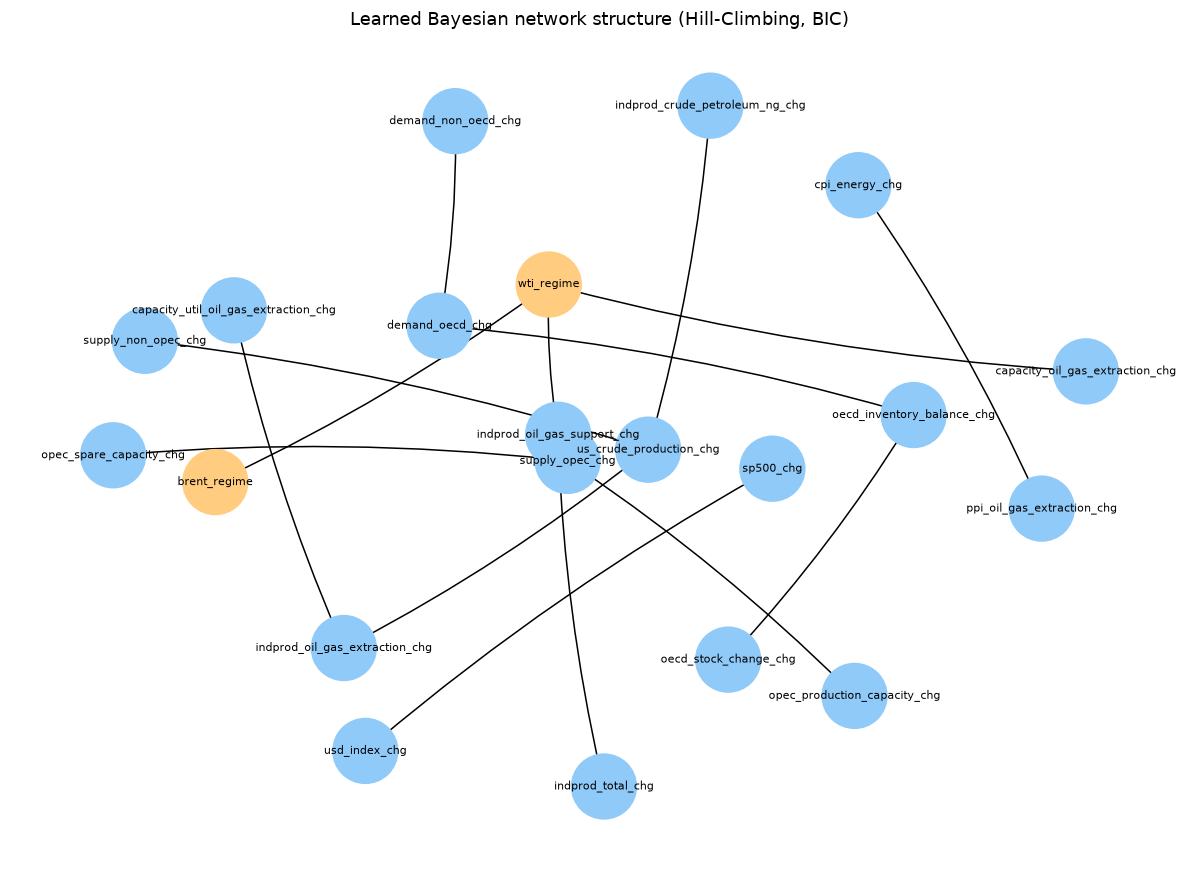

In [13]:
import networkx as nx

graph = nx.DiGraph(bn.edges)
fig, ax = plt.subplots(figsize=(11, 8))
pos = nx.spring_layout(graph, seed=7, k=1.1)
node_colors = ["#ffcc80" if "regime" in n else "#90caf9" for n in graph.nodes]
nx.draw_networkx_nodes(graph, pos, node_color=node_colors, node_size=1800, ax=ax)
nx.draw_networkx_labels(graph, pos, font_size=7, ax=ax)
nx.draw_networkx_edges(graph, pos, arrowsize=15, ax=ax, connectionstyle="arc3,rad=0.05")
ax.set_title("Learned Bayesian network structure (Hill-Climbing, BIC)")
ax.axis("off")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "bayesian_network_structure.png", dpi=150)
plt.show()

## Step 6 — Structure-stability check (training vs. validation split)

A lightweight temporal split (chronological, not shuffled, since this is
time-series data): fit Hill-Climbing on the first 80% of months
("training"), and check what fraction of the full-sample edges are also
recovered on that subset. This is a sanity check on structural stability,
not yet the formal `DatasetSplitter`/forecast-accuracy evaluation, which
is GWP3's job once the full train/validation/test harness is built.

In [14]:
split_point = int(len(discrete_panel) * 0.8)
train_panel = discrete_panel.iloc[:split_point]
validation_panel = discrete_panel.iloc[split_point:]
print(
    f"Training months: {len(train_panel)} "
    f"({train_panel.index.min().date()} -> {train_panel.index.max().date()})"
)
print(
    f"Validation months: {len(validation_panel)} "
    f"({validation_panel.index.min().date()} -> {validation_panel.index.max().date()})"
)

bn_train = OilPriceBayesianNetwork(scoring_method="bic-d", max_indegree=3, tabu_length=50)
bn_train.fit_structure(train_panel)

full_edges = {frozenset(e) for e in bn.edges}
train_edges = {frozenset(e) for e in bn_train.edges}
overlap = full_edges & train_edges
print(f"\nFull-sample edges: {len(full_edges)}; training-subset edges: {len(train_edges)}")
print(
    f"Edges recovered in both: {len(overlap)} "
    f"({len(overlap) / len(full_edges):.0%} of full-sample edges)"
)

Training months: 132 (2007-07-31 -> 2018-06-30)
Validation months: 34 (2018-07-31 -> 2021-04-30)


C:\Users\fdeba001\Downloads\WQU\oil-price-risk-capstone\src\oilbn\models\bayesian_network.py:77: FutureWarning: HillClimbSearch is deprecated and will be removed in v1.3.0. Please use
            pgmpy.causal_discovery.HillClimbSearch instead.
  searcher = HillClimbSearch(data)



Full-sample edges: 15; training-subset edges: 14
Edges recovered in both: 14 (93% of full-sample edges)


## Summary and artifacts produced

- `HiddenMarkovRegimeModel` (forward/backward/Viterbi/Baum-Welch, from
  scratch in NumPy) validated on a toy example, then fit to WTI and Brent
  daily log returns to decode bear/stagnant/bull regimes.
- Regime spell-duration statistics: WTI bear spells average 21.5 trading
  days (sharp, short-lived crashes); bull spells average 140.7 days
  (slow, grinding rallies) — consistent with the volatility-clustering
  stylized fact from GWP1.
- A 24-variable discrete monthly panel (2 HMM-decoded regimes + 22
  tercile-discretized month-over-month changes), 166 months.
- `OilPriceBayesianNetwork` (Hill-Climbing + BIC structure learning,
  Bayesian/BDeu parameter learning) recovered 15 edges, including the
  economically sensible `brent_regime -> wti_regime` link and a
  `wti_regime` Markov blanket of `{brent_regime, capacity_oil_gas_extraction_chg,
  indprod_oil_gas_support_chg}`.
- A chronological 80/20 structure-stability check recovered 93% of the
  full-sample edges on the training subset alone.
- Figures saved to `reports/GWP2/figures/`: `baum_welch_toy_convergence.png`,
  `wti_regimes.png`, `brent_regimes.png`, `bayesian_network_structure.png`.